# Template Matching für den Chirp-Mass-Proxy (ET-HF-IMBH)

Bank wird einmal erzeugt und gespeichert, die Filterung läuft batchweise auf der GPU. Die Extrinsik wird **nicht** mehr aus der Injektion übernommen (blind). Die Logik steht in `chirp_mass_matcher.py`.

In [1]:
import os
os.environ["CUDA_VISIBLE_DEVICES"] = "3"
import numpy as np, matplotlib.pyplot as plt, torch
from dingo.core.posterior_models.build_model import build_model_from_kwargs
from dingo.gw.injection import Injection
import chirp_mass_matcher as cmm
from dingo.gw.noise.asd_dataset import ASDDataset

MODEL_NAME = "stage1"   # anpassen
MODEL_PATH = f"/scratch/tpausch/models/{MODEL_NAME}/model_latest.pt"
BANK_PATH  = f"/scratch/tpausch/test_data/{MODEL_NAME}/chirp_mass_bank.pt"
INJECTION_DIR = f"/scratch/tpausch/test_data/{MODEL_NAME}/injections"

pm = build_model_from_kwargs(filename=MODEL_PATH, device="cpu", load_training_info=False)
pm_metadata = pm.metadata
generator = Injection.from_posterior_model_metadata(pm.metadata)
cfg = cmm.BankConfig.from_metadata(pm.metadata)   # f 6-256, dF 0.125, Mc 75-1200, m1/m2-Constraints
del pm

# ASD fuer den Sanity-Check (signal() liefert keinen ASD); Pfad wie in train_settings stage_0
ASD_PATH = "/scratch/tpausch/ASD/asds_ET_T8.hdf5"
asd_dataset = ASDDataset(file_name=ASD_PATH)
generator.asd = {k: v[0] for k, v in asd_dataset.asds.items()}
print(cfg)

/home/tpausch/ET-Dingo/dingo/gw/__init__.py:3: UserWarning: Wswiglal-redir-stdio:

SWIGLAL standard output/error redirection is enabled in IPython.
This may lead to performance penalties. To disable locally, use:

with lal.no_swig_redirect_standard_output_error():
    ...

To disable globally, use:

lal.swig_redirect_standard_output_error(False)

Note however that this will likely lead to error messages from
LAL functions being either misdirected or lost when called from
Jupyter notebooks.

To suppress this warning, use:

import warnings
warnings.filterwarnings("ignore", "Wswiglal-redir-stdio")
import lal

  import lal

WARNING!

This object was created using Dingo version 0.1.dev1230+gc9da5d765 < 0.9.0, which broke backwards compatibility.
For models trained prior to this change, new inference results will be unreliable.
Previously-generated result files should be used with caution.
Reasons for backward compatibility breaking:

v0.9.0: Change to window factor usage, see https://git.li

Putting posterior model to device cpu.
Setting spin_conversion_phase = 0.0. Using this value for the phase parameter for conversion to cartesian spins.
Loading dataset from /scratch/tpausch/ASD/asds_ET_T8.hdf5.
BankConfig(f_min=6.0, f_max=256.0, delta_f=0.125, mc_min=50.0, mc_max=1000.0, m1_range=(30.0, 3000.0), m2_range=(30.0, 3000.0), d_l_ref=1000.0, dlog_mc=0.03, mc_step=None, mass_ratios=(0.125, 0.2, 0.35, 0.6, 1.0), spins=(-0.6, 0.0, 0.6), spin_mode='pairs', theta_jn=(0.6, 1.5708), phases=(0.0,))


## 1. Bank bauen (einmalig)
Gitter: Mc geometrisch (3 %), q ∈ 5 Werte, χ₁,χ₂ ∈ {−0.6, 0, 0.6}, θ_jn ∈ {0.6, π/2}. Alles in `BankConfig` änderbar. Mit `n_workers` parallelisieren.

In [2]:
# if os.path.exists(BANK_PATH):
#     bank = cmm.TemplateBank.load(BANK_PATH, device="cuda")
# else:
#     h, grid = cmm.build_bank(cfg, cmm.make_dingo_h0(generator, cfg), n_workers=8)
#     bank = cmm.TemplateBank(h, grid, cfg, device="cuda")
#     bank.save(BANK_PATH)
# print(len(bank), "Templates,", bank.n_mc, "Mc-Gitterpunkte")
# matcher = cmm.ChirpMassMatcher(bank, oversample=4, t_window=0.125, chunk=256)

In [3]:
%%capture
import importlib; importlib.reload(cmm)
cfg3 = cmm.BankConfig.from_metadata(pm_metadata, mc_step=5.0)   # Rest wie in der ersten Bank
BANK3_PATH = BANK_PATH.replace(".pt", "_step5.pt")
h, grid = cmm.build_bank(cfg3, cmm.make_dingo_h0(generator, cfg3), n_workers=20)
bank3 = cmm.TemplateBank(h, grid, cfg3, device="cuda"); bank3.save(BANK3_PATH)
matcher = cmm.ChirpMassMatcher(bank3)

## 2. Sanity-Check (rauschfrei)
Fitting-Faktor sollte nahe 1 liegen, `mc_refined` nahe am wahren Wert. Schlägt das fehl, stimmt meist eine Konvention nicht (Array-Länge, `h_plus`-API, Zeitfenster).

In [4]:
np.random.seed(0)
for _ in range(5):
    theta = {k: float(v) for k, v in generator.prior.sample().items()}
    cmm.sanity_check(matcher, generator, theta)

Generation with parameters (1.8182808595198332e+33, 9.364117764868589e+32, 0.0, 0.0, -0.33878931120067485, 0.0, 0.0, -0.000695867661886543, 3.085677581491367e+24, 1.4373580304360072, 5.846278308127394, 0.0, 0.0, 0.0, 0.125, 6.0, 256.0, 20.0, None, 101) likely numerically unstable due to multibanding, turn off multibanding.
Mc_true=565.1  Mc_refined=584.0  FF=0.995  rho_opt=72.0
Generation with parameters (2.9355517692278103e+33, 7.456084860900054e+32, 0.0, 0.0, 0.06465048274529578, 0.0, 0.0, 0.17297552164663074, 3.085677581491367e+24, 1.4428545971747844, 3.9599928216732496, 0.0, 0.0, 0.0, 0.125, 6.0, 256.0, 20.0, None, 101) likely numerically unstable due to multibanding, turn off multibanding.
Mc_true=620.0  Mc_refined=610.5  FF=0.987  rho_opt=69.1
Generation with parameters (3.1444786496129015e+33, 9.972781468224694e+32, 0.0, 0.0, -0.330655166148205, 0.0, 0.0, -0.6191850765204191, 3.085677581491367e+24, 2.3117055277209198, 0.5976026005679005, 0.0, 0.0, 0.0, 0.125, 6.0, 256.0, 20.0, N

In [5]:
lalwf = cmm.LALWaveform.from_generator(generator, cfg)
print(lalwf.name, lalwf.f_ref)                      # erwartet: IMRPhenomXPHM 20.0
asd0 = next(iter(generator.asd.values()))
m = cmm.check_lal_vs_dingo(generator, cfg, lalwf, n=10, asd=asd0)   # alle > 0.9999?

refiner = cmm.LocalRefiner(matcher, lalwf)
res = cmm.evaluate_injections(matcher, INJECTION_DIR, max_injections=100,
                              refiner=refiner, n_workers=20)
res[[c for c in res if c.startswith("inside_")]].mean()

IMRPhenomXPHM 20.0
Mc=  337.0 q=0.36 theta_jn=0.89  match=1.000000  roh=1.000000  Amplitudenverh.=1.0000
Mc=  307.8 q=0.76 theta_jn=0.89  match=1.000000  roh=1.000000  Amplitudenverh.=1.0000
Generation with parameters (4.095319933924267e+33, 6.322657082762183e+32, 0.0, 0.0, 0.41337980357389925, 0.0, 0.0, -0.5838198829153938, 3.0856775814913673e+25, 0.7577884157395937, 3.402101183476623, 0.0, 0.0, 0.0, 0.125, 6.0, 256.0, 20.0, None, 101) likely numerically unstable due to multibanding, turn off multibanding.
Mc=  652.3 q=0.15 theta_jn=0.76  match=1.000000  roh=1.000000  Amplitudenverh.=1.0000
Mc=  122.7 q=0.49 theta_jn=1.22  match=1.000000  roh=1.000000  Amplitudenverh.=1.0000
Mc=  315.9 q=0.46 theta_jn=1.19  match=1.000000  roh=1.000000  Amplitudenverh.=1.0000
Mc=  393.2 q=0.47 theta_jn=1.52  match=1.000000  roh=1.000000  Amplitudenverh.=1.0000
Mc=  214.3 q=0.90 theta_jn=1.43  match=1.000000  roh=1.000000  Amplitudenverh.=1.0000
Mc=  296.6 q=0.42 theta_jn=2.15  match=1.000000  roh=1.00

inside_mc_argmax      0.33
inside_mc_refined     0.34
inside_mc_weighted    0.33
inside_mc_median      0.36
inside_mc_mean        0.35
inside_mc_local       0.68
dtype: float64

## 3. Injektionen auswerten

In [6]:
%%capture
cfg = cmm.BankConfig.from_metadata(pm_metadata, dlog_mc=0.02,
        mass_ratios=tuple(np.linspace(0.125, 1, 12)), spin_mode="equal",
        spins=tuple(np.linspace(-0.9, 0.9, 7)),
        phases=tuple(np.linspace(0, 2*np.pi, 4, endpoint=False)))
h, grid = cmm.build_bank(cfg, cmm.make_dingo_h0(generator, cfg), n_workers=20)
bank = cmm.TemplateBank(h, grid, cfg); matcher = cmm.ChirpMassMatcher(bank)
refiner = cmm.LocalRefiner(matcher, cmm.make_dingo_h0(generator, cfg), n_starts=3)
res = cmm.evaluate_injections(matcher, INJECTION_DIR, max_injections=1, refiner=refiner)
res[[c for c in res if c.startswith("inside_")]].mean()

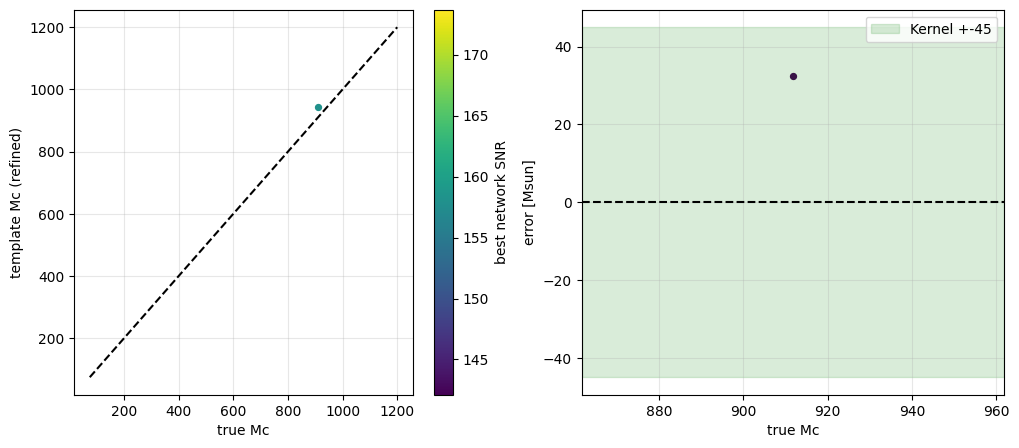

bin
7    [32.4, 32.4, 32.4]
Name: err_mc_refined, dtype: object
Anteil innerhalb Kernel +-50 Msun: 1.0


In [7]:
fig, ax = plt.subplots(1, 2, figsize=(12, 5))
sc = ax[0].scatter(res.chirp_mass_true, res.mc_refined, c=res.snr_best, s=18, cmap="viridis")
lim = [75, 1200]; ax[0].plot(lim, lim, "k--"); plt.colorbar(sc, ax=ax[0], label="best network SNR")
ax[0].set(xlabel="true Mc", ylabel="template Mc (refined)")
ax[1].scatter(res.chirp_mass_true, res.err_mc_refined, s=18, c=res.snr_best)
ax[1].axhspan(-45, 45, color="g", alpha=0.15, label="Kernel +-45")
ax[1].axhline(0, color="k", ls="--"); ax[1].set(xlabel="true Mc", ylabel="error [Msun]"); ax[1].legend()
for a in ax: a.grid(alpha=0.3)
plt.show()

# Fehlerquantile in Mc-Bins -> Grundlage fuer die Kernel-Breite
bins = np.geomspace(75, 1200, 8)
res["bin"] = np.digitize(res.chirp_mass_true, bins)
print(res.groupby("bin").err_mc_refined.agg(lambda x: np.quantile(np.abs(x), [0.5, 0.9, 0.99]).round(1).tolist()))

#print amount of injections that are inside the kernel +-50 Msun
print("Anteil innerhalb Kernel +-50 Msun:", (np.abs(res.err_mc_refined) < 50).mean())   
